# VRP 02 — Long ATM straddle, held to settlement

**Branch:** Volatility Risk Premium · **Discussion:** `discussions/Volatility_Risk_Premium/007_claude_long_straddle_preregistration.md` · **Code:** `src/data_engineering/modeling/vrp_long_straddle.py`

Does a **buyer** of the 0DTE ATM straddle, paying the ask and the taker fee, recover the cost at settlement on average? No hedge: the spread is paid once and settlement is cash at the exchange delivery price.

Pre-registered (fixed in the module before this notebook was first run on real data):

- Entries every full hour with 2h ≤ TTE ≤ 20h; strike nearest the forward with both legs two-sided.
- $R = \dfrac{|S_T-K|}{\text{ask}_C+\text{ask}_P+\text{fees}} - 1$ (coin premium valued at $S_T/F$ for inverse families).
- $M$ = mean over sessions of the session-pooled mean $R$; 95% session-bootstrap CI.
- **CI > 0 → LONG_EDGE_CANDIDATE · CI < 0 → NO_LONG_EDGE · otherwise INCONCLUSIVE.**
- Sessions on or after 2026-11-07 (VRP confirmation window) are never loaded.

Environment (optional): `VRP02_OFFLINE=1` skips the delivery-price download; `VRP02_ASSETS=BTC,ETH`; `VRP02_N_BOOT`.

In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import duckdb
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 250)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from data_engineering.modeling import vrp_long_straddle as ls
OFFLINE = os.getenv('VRP02_OFFLINE', '').strip() == '1'
ASSETS = [x.strip().upper() for x in os.getenv('VRP02_ASSETS', '').split(',') if x.strip()]
N_BOOT = int(os.getenv('VRP02_N_BOOT', str(ls.N_BOOT)))
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Risk_Premium' / '02'
OUT.mkdir(parents=True, exist_ok=True)
print('VRP 02', ls.VERSION, ls.selftest())
print(json.dumps(ls.registration(), indent=2))

VRP 02 0.1.0 {'version': '0.1.0', 'fair_M': -0.0543, 'rich_M': -0.5778, 'cheap_M': 1.0234, 'ok': True}
{
  "version": "0.1.0",
  "confirmation_start_excluded": "2026-11-07",
  "tte_min": [
    120,
    1200
  ],
  "entry_grid_min": 60,
  "fee_rate": 0.0003,
  "fee_cap": 0.125,
  "delivery_fee_rate_sensitivity": 0.00015,
  "n_boot": 4000,
  "seed": 7007,
  "primary_unit": "R_net = payoff/(ask+fee) - 1",
  "primary_statistic": "mean over sessions of session-pooled mean R_net",
  "decision": "CI>0 LONG_EDGE_CANDIDATE; CI<0 NO_LONG_EDGE; else INCONCLUSIVE"
}


## 1. Quotes → straddles

In [2]:
con = duckdb.connect(str(DB_PATH), read_only=True)
try:
    have = set(con.execute('DESCRIBE normalized_option_chain').df()['column_name'])
    need = [c for c in ls.CHAIN_COLUMNS if c != 'settlement_currency']
    miss = sorted(set(need) - have)
    if miss:
        raise RuntimeError(f'normalized_option_chain lacks {miss}')
    cols = need + (['settlement_currency'] if 'settlement_currency' in have else [])
    where_assets = ('AND n.underlying IN (' + ','.join(repr(a) for a in ASSETS) + ')') if ASSETS else ''
    chain = con.execute(f'''
        WITH prim AS (SELECT DISTINCT state_id, option_family_id FROM primary_option_surface_feature_state)
        SELECT {', '.join('n.' + c for c in cols)}
        FROM normalized_option_chain n
        JOIN prim p ON p.state_id = n.state_id AND p.option_family_id = n.option_family_id
        WHERE n.minutes_to_expiry BETWEEN {ls.MIN_TTE_MIN} AND {ls.MAX_TTE_MIN}
          AND EXTRACT(minute FROM n.state_time) % {ls.ENTRY_GRID_MIN} = 0
          AND n.state_time < TIMESTAMPTZ '{ls.VRP_CONFIRMATION_START.isoformat()}'
          AND abs(ln(n.strike / n.option_forward_price)) < 0.05
          {where_assets}
    ''').df()
finally:
    con.close()
if 'settlement_currency' not in chain:
    chain['settlement_currency'] = None
legs = ls.prepare_legs(chain)
st = ls.select_straddles(legs)
print(f'chain rows {len(chain):,} | legs {len(legs):,} | straddles {len(st):,} | sessions {st.session.nunique()}')
display(st.groupby('underlying').agg(straddles=('K', 'size'), sessions=('session', 'nunique'),
                                     median_spread_share=('spread_share', 'median'),
                                     median_fee_share=('fee_usd', lambda f: float(np.median(f / st.loc[f.index, 'ask_usd'])))).round(4))

chain rows 61,908 | legs 61,908 | straddles 2,515 | sessions 20


,straddles,sessions,median_spread_share,median_fee_share
underlying,,,,
AVAX,372,20,0.1200,0.0288
BTC,375,20,0.2258,0.0770
ETH,375,20,0.2194,0.0648
HYPE,361,20,0.2005,0.0344
SOL,367,20,0.2069,0.0390
TRX,325,20,0.2353,0.0805
XRP,340,20,0.1949,0.0337


## 2. Settlement price: exchange delivery price, approximate TWAP as fallback and check

In [3]:
sessions = sorted(st.session.unique())
con = duckdb.connect(str(DB_PATH), read_only=True)
try:
    idx = con.execute(f'''
        SELECT state_time, underlying, futures_index_price FROM time_series_feature_state
        WHERE state_time < TIMESTAMPTZ '{ls.VRP_CONFIRMATION_START.isoformat()}'
    ''').df()   # UTC window filtering is done in pandas (independent of the DuckDB session time zone)
finally:
    con.close()
approx = ls.approx_settlement(idx, sessions)
names = sorted({ls.index_name(u, c) for u, c in zip(st.underlying, st.settlement_currency)})
cache = OUT / '02_delivery_prices.csv'
if OFFLINE:
    delivery = pd.read_csv(cache, dtype={'session': str}) if cache.exists() else pd.DataFrame(columns=['index_name', 'session', 'delivery_price'])
else:
    delivery = ls.fetch_delivery_prices(names, cache_csv=cache)
delivery = delivery[delivery.session.isin(sessions)]
x = ls.straddle_pnl(ls.attach_settlement(st, delivery, approx))
print('settlement source:', x.drop_duplicates(['session', 'underlying']).settle_source.value_counts().to_dict())
chk = x.drop_duplicates(['session', 'underlying']).dropna(subset=['delivery_price', 'settle_approx'])
if len(chk):
    chk = chk.assign(diff_bps=1e4 * np.log(chk.settle_approx / chk.delivery_price))
    settle_check = chk.groupby('underlying').diff_bps.describe()[['count', 'mean', 'std', 'min', 'max']]
    display(settle_check.round(2))
else:
    settle_check = pd.DataFrame()
    print('no overlap between exchange and approximate settlement')

settlement source: {'exchange': 140}


,count,mean,std,min,max
underlying,,,,,
AVAX,19.0,0.24,6.94,-12.81,17.94
BTC,19.0,-0.17,1.86,-4.80,2.88
ETH,19.0,-0.05,2.58,-5.16,3.71
HYPE,19.0,0.83,4.32,-10.64,5.66
SOL,19.0,-0.04,4.66,-9.69,13.01
TRX,19.0,0.16,0.57,-0.67,1.91
XRP,19.0,0.04,3.70,-6.49,8.48


## 3. Primary decision

In [4]:
prim = ls.primary(x, n_boot=N_BOOT)
print(json.dumps(prim, indent=2))
print('VERDICT:', prim['verdict'])

{
  "n_sessions": 20,
  "M": -0.266365891646526,
  "ci_low": -0.3893195242293167,
  "ci_high": -0.12166118812904109,
  "loso_min": -0.3107301818402613,
  "loso_max": -0.25207399203875774,
  "share_sessions_positive": 0.15,
  "verdict": "NO_LONG_EDGE",
  "n_straddles": 2515,
  "n_session_assets": 140
}
VERDICT: NO_LONG_EDGE


## 4. Reported, no decision

In [5]:
cols = list(ls.REPORT_COLS)
tab_all = ls.report_table(x, None, cols, n_boot=1000)
tab_asset = ls.report_table(x, 'underlying', ['R_net', 'R_gross', 'pnl_long_net_bps', 'move_over_implied', 'spread_share'], n_boot=1000)
tab_tte = ls.report_table(x, 'tte_bucket', ['R_net', 'R_gross', 'move_over_implied', 'spread_share'], n_boot=1000)
tab_src = ls.report_table(x, 'settle_source', ['R_net'], n_boot=1000)
keep = ['group', 'level', 'metric', 'n_straddles', 'n_sessions', 'M', 'ci_low', 'ci_high', 'loso_min', 'loso_max', 'share_sessions_positive']
for t in (tab_all, tab_asset, tab_tte, tab_src):
    display(t[[c for c in keep if c in t]].round(4))

,group,level,metric,n_straddles,n_sessions,M,ci_low,ci_high,loso_min,loso_max,share_sessions_positive
0,all,all,R_net,2515,20,-0.2664,-0.3878,-0.1191,-0.3107,-0.2521,0.15
1,all,all,R_gross,2515,20,-0.2288,-0.3560,-0.0738,-0.2751,-0.2137,0.20
2,all,all,R_net_delivery_fee,2515,20,-0.2783,-0.3999,-0.1314,-0.3227,-0.2640,0.15
3,all,all,R_mid,2515,20,-0.1367,-0.2805,0.0380,-0.1881,-0.1193,0.25
4,all,all,pnl_long_net_bps,2515,20,-38.2120,-57.3172,-15.8651,-45.4807,-34.9518,0.15
5,all,all,pnl_short_bid_net_bps,2515,20,1.0320,-21.1563,19.9635,-2.0816,8.3970,0.65
6,all,all,move_over_implied,2515,20,0.8475,0.7003,1.0212,0.7960,0.8678,1.00
7,all,all,spread_share,2515,20,0.2483,0.2262,0.2723,0.2410,0.2516,1.00


,group,level,metric,n_straddles,n_sessions,M,ci_low,ci_high,loso_min,loso_max,share_sessions_positive
0,underlying,AVAX,R_net,372,20,0.0371,-0.2578,0.4273,-0.1065,0.0722,0.40
1,underlying,AVAX,R_gross,372,20,0.0698,-0.2339,0.4709,-0.0782,0.1061,0.40
2,underlying,AVAX,pnl_long_net_bps,372,20,-2.5961,-67.0903,81.4512,-33.7549,6.3569,0.40
3,underlying,AVAX,move_over_implied,372,20,1.1772,0.8396,1.6191,1.0193,1.2189,1.00
4,underlying,AVAX,spread_share,372,20,0.1852,0.1600,0.2109,0.1782,0.1906,1.00
5,underlying,BTC,R_net,375,20,-0.2815,-0.4658,-0.0663,-0.3394,-0.2522,0.20
6,underlying,BTC,R_gross,375,20,-0.2263,-0.4246,0.0049,-0.2888,-0.1948,0.20
7,underlying,BTC,pnl_long_net_bps,375,20,-23.2696,-38.8030,-5.1576,-28.3320,-21.0450,0.15
8,underlying,BTC,move_over_implied,375,20,0.9091,0.6814,1.1745,0.8369,0.9385,1.00
9,underlying,BTC,spread_share,375,20,0.2779,0.2410,0.3295,0.2582,0.2831,1.00


,group,level,metric,n_straddles,n_sessions,M,ci_low,ci_high,loso_min,loso_max,share_sessions_positive
0,tte_bucket,16-20h,R_net,535,20,-0.2393,-0.3755,-0.0792,-0.2779,-0.2215,0.20
1,tte_bucket,16-20h,R_gross,535,20,-0.2102,-0.3518,-0.0433,-0.2505,-0.1917,0.20
2,tte_bucket,16-20h,move_over_implied,535,20,0.8362,0.6818,1.0101,0.7913,0.8585,1.00
3,tte_bucket,16-20h,spread_share,535,20,0.1430,0.1255,0.1618,0.1366,0.1455,1.00
4,tte_bucket,2-4h,R_net,336,20,-0.3217,-0.4844,-0.1242,-0.3968,-0.2964,0.20
5,tte_bucket,2-4h,R_gross,336,20,-0.2750,-0.4488,-0.0658,-0.3548,-0.2481,0.20
6,tte_bucket,2-4h,move_over_implied,336,20,0.8757,0.6352,1.1585,0.7728,0.9053,1.00
7,tte_bucket,2-4h,spread_share,336,20,0.4868,0.4394,0.5401,0.4701,0.4942,1.00
8,tte_bucket,4-8h,R_net,537,20,-0.2788,-0.4263,-0.1137,-0.3242,-0.2598,0.20
9,tte_bucket,4-8h,R_gross,537,20,-0.2368,-0.3947,-0.0652,-0.2846,-0.2167,0.25


,group,level,metric,n_straddles,n_sessions,M,ci_low,ci_high,loso_min,loso_max,share_sessions_positive
0,settle_source,exchange,R_net,2515,20,-0.2664,-0.3878,-0.1191,-0.3107,-0.2521,0.15


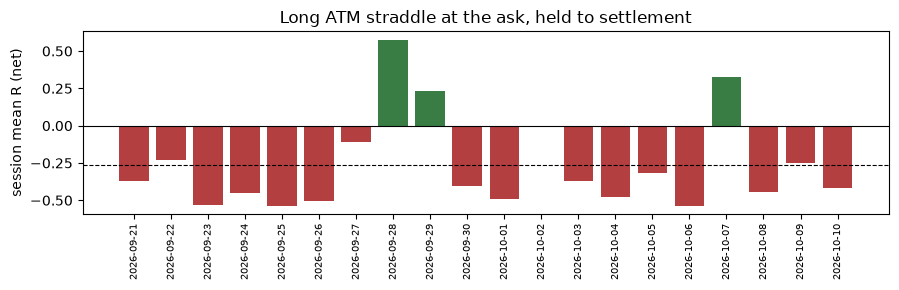

In [6]:
import matplotlib.pyplot as plt
sm = ls.session_means(x, 'R_net')
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(sm)), sm.values, color=np.where(sm.values > 0, '#3a7d44', '#b33f40'))
ax.axhline(0, color='k', lw=0.8); ax.axhline(prim.get('M', np.nan), color='k', ls='--', lw=0.8)
ax.set_xticks(range(len(sm))); ax.set_xticklabels(sm.index, rotation=90, fontsize=7)
ax.set_ylabel('session mean R (net)'); ax.set_title('Long ATM straddle at the ask, held to settlement')
plt.tight_layout(); plt.show()

## 5. Outputs

In [7]:
session_asset = (x.groupby(['session', 'underlying'])
                 .agg(n=('R_net', 'size'), R_net=('R_net', 'mean'), R_gross=('R_gross', 'mean'),
                      pnl_long_net_bps=('pnl_long_net_bps', 'mean'), move_over_implied=('move_over_implied', 'mean'),
                      S_T=('S_T', 'first'), settle_source=('settle_source', 'first')).reset_index())
session_asset.to_csv(OUT / '02_session_asset.csv', index=False, float_format='%.6g')
pd.concat([tab_all, tab_asset, tab_tte, tab_src], ignore_index=True).to_csv(OUT / '02_report_tables.csv', index=False, float_format='%.6g')
if len(settle_check):
    settle_check.to_csv(OUT / '02_settlement_check.csv', float_format='%.4g')
(OUT / '02_decision.json').write_text(json.dumps({'primary': prim, 'registration': ls.registration()}, indent=2, default=float))
meta = {'module': '02_long_straddle_settlement', 'version': ls.VERSION, 'offline': OFFLINE, 'assets_filter': ASSETS,
        'n_straddles': int(len(x)), 'sessions': [sessions[0], sessions[-1]] if sessions else [],
        'settle_sources': x.drop_duplicates(['session', 'underlying']).settle_source.value_counts().to_dict(),
        'index_names': names}
(OUT / '02_run_metadata.json').write_text(json.dumps(meta, indent=2, default=str))
print(json.dumps(meta, indent=2, default=str))

{
  "module": "02_long_straddle_settlement",
  "version": "0.1.0",
  "offline": false,
  "assets_filter": [],
  "n_straddles": 2515,
  "sessions": [
    "2026-09-21",
    "2026-10-10"
  ],
  "settle_sources": {
    "exchange": 140
  },
  "index_names": [
    "avax_usdc",
    "btc_usdc",
    "eth_usdc",
    "hype_usdc",
    "sol_usdc",
    "trx_usdc",
    "xrp_usdc"
  ]
}
